In [1]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 130)

In [2]:
# Google Colab
PATH = Path("/content/processed")

# Local project directory (comment the Colab line above and uncomment this one)
# PATH = Path("diplomacy-deception-detection/artifacts/processed")

for task in ["actual_lie", "suspected_lie"]:
    file = PATH / task / "train.jsonl"
    print(file, ":", file.is_file())

/content/processed/actual_lie/train.jsonl : True
/content/processed/suspected_lie/train.jsonl : True


In [3]:
def read_jsonl(file):
    with open(file, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

datasets = {}
for task in ["actual_lie", "suspected_lie"]:
    datasets[task] = pd.DataFrame(read_jsonl(PATH / task / "train.jsonl"))
    print(task, ":", len(datasets[task]), "training messages")

assert all(frame["target"].isin([0, 1]).all() for frame in datasets.values())
display(datasets["actual_lie"][["message_id", "message", "target"]].head())

actual_lie : 13132 training messages
suspected_lie : 12025 training messages


,message_id,message,target
0,1:0:0,"Germany!\n\nJust the person I want to speak with. I have a somewhat crazy idea that I’ve always wanted to try with I/G, but I’...",0
1,1:0:1,"You've whet my appetite, Italy. What's the suggestion?",0
2,1:0:2,👍,0
3,1:0:3,It seems like there are a lot of ways that could go wrong...I don't see why France would see you approaching/taking Munich--wh...,0
4,1:0:4,"Yeah, I can’t say I’ve tried it and it works, cause I’ve never tried it or seen it. But how I think it would work is (a) my Sp...",0


#### Harbingers categories

In [4]:
LEXICON = {'claim': "accordingly|as a result|consequently|conclude that|clearly|demonstrates that|entails|follows that|hence|however|implies|in fact|in my opinion|in short|in conclusion|indicates that|it follows that|it is highly probable that|it is my contention|it should be clear that|i believe|i mean|i think|must be that|on the contrary|points to the conclusions|proves that|shows that|so|suggests that|the most obvious explanation|the point i'm trying to make|therefore|thus|the truth of the matter|to sum up|we may deduce", 'subjectivity': 'abandoned|abandonment|abandon|abase|abasement|abash|abate|abdicate|aberration|abhor|abhorred|abhorrence|abhorrent|abhorrently|abhors|abidance|abide|abject|abjectly|abjure|abilities|ability|able|abnormal|abolish|abominable|abominably|abominate|abomination|above|above-average|abound|abrade|abrasive|abrupt|abscond|absence|absentee|absent-minded|absolve|absolute|absolutely|absorbed|absurd|absurdity|absurdly|absurdness|abundant|abundance|abuse|abuses|abusive|abysmal|abysmally|abyss|accede|accentuate|accept|acceptance|acceptable|accessible|accidental|acclaim|acclaimed|acclamation|accolade|accolades|accommodative|accomplish|accomplishment|accomplishments|accord|accordance|accordantly|accost|accountable|accurate|accurately|accursed|accusation|accusations|accuse|accuses|accusing|accusingly|acerbate|acerbic|acerbically|ache|achievable|achieve|achievement|achievements|acknowledge|acknowledgement|acquit|acrid|acridly|acridness|acrimonious|acrimoniously|acrimony|active|activist|actual|actuality|actually|acumen|adamant|adamantly|adaptable|adaptability|adaptive|addict|addiction|adept|adeptly|adequate|adherence|adherent|adhesion|admirable|admirer|admirably|admiration|admire|admiring|admiringly|admission|admit|admittedly|admonish|admonisher|admonishingly|admonishment|admonition', 'expansion': 'additionally|also|alternatively|although|as an alternative|as if|as though|as well|besides|either or|else|except|finally|for example|for instance|further|furthermore|however|in addition|in fact|in other words|in particular|in short|in sum|in the end|in turn|indeed|instead|later|lest|likewise|meantime|meanwhile|moreover|much as|neither nor|next|nonetheless|nor|on the other hand|otherwise|overall|plus|rather|separately|similarly|specifically|then|ultimately|unless|until|when|while|yet', 'contingency': 'accordingly|as a result|as long as|because|consequently|hence|if and when|if then|in the end|in turn|indeed|insofar as|lest|now that|once|since|so that|then|thereby|therefore|thus|unless|until|when', 'premise': "after all|assuming that|as|as indicated by|as shown|besides|because|deduced|derived from|due to|firstly|follows from|for|for example|for instance|for one thing|for the reason that|furthermore|given that|in addition|in light of|in that|in view of|in view of the fact that|indicated by|is supported by|may be inferred|moreover|owing to|researchers found that|secondly|this can be seen from since|since the evidence is|what's more|whereas", 'temporal_future': 'after|afterward|as soon as|by then|finally|in the end|later|next|once|then|thereafter|till|ultimately|until', 'temporal_other': 'also|as long as|before|before and after|earlier|in turn|meantime|meanwhile|now that|previously|simultaneously|since|still|when|when and if|while', 'comparisons': 'after|although|as if|as though|besides|by comparison|by contrast|conversely|earlier|however|in contrast|in fact|in the end|indeed|instead|meanwhile|much as|neither nor|nevertheless|nonetheless|nor|on the contrary|on the one hand on the other hand|on the other hand|previously|rather|regardless|still|then|though|when|whereas|while|yet'}

In [5]:
category_table = pd.DataFrame([
    {"category": category,
     "number_of_terms": len([term for term in terms.split("|") if term.strip()]),
     "first_five_terms": ", ".join(terms.split("|")[:5])}
    for category, terms in LEXICON.items()
])
display(category_table)

,category,number_of_terms,first_five_terms
0,claim,37,"accordingly, as a result, consequently, conclude that, clearly"
1,subjectivity,136,"abandoned, abandonment, abandon, abase, abasement"
2,expansion,54,"additionally, also, alternatively, although, as an alternative"
3,contingency,24,"accordingly, as a result, as long as, because, consequently"
4,premise,35,"after all, assuming that, as, as indicated by, as shown"
5,temporal_future,14,"after, afterward, as soon as, by then, finally"
6,temporal_other,16,"also, as long as, before, before and after, earlier"
7,comparisons,34,"after, although, as if, as though, besides"


In [6]:
len(LEXICON)


8

#### term-matching patterns

In [7]:
def compile_category(terms):
    items = [item.strip().replace("’", "'") for item in terms.split("|") if item.strip()]
    pattern = "|".join(re.escape(x) for x in sorted(set(items), key=len, reverse=True))
    return re.compile(r"(?<!\w)(?:" + pattern + r")(?!\w)", flags=re.IGNORECASE)

patterns = {category: compile_category(words) for category, words in LEXICON.items()}

def harbingers_features(messages):
    return np.array([
        [len(pattern.findall(message.lower().replace("’", "'")))
         for pattern in patterns.values()]
        for message in messages
    ], dtype=float)


print("Compiled categories:", list(patterns.keys()))

Compiled categories: ['claim', 'subjectivity', 'expansion', 'contingency', 'premise', 'temporal_future', 'temporal_other', 'comparisons']


#### how category matching works

In [8]:
sample_messages = [
    "I think we should cooperate because it will help us.",
    "However, if you attack, then I will respond.",
    "We can move together next season.",
    "Hello Germany!"
]

sample_features = pd.DataFrame(
    harbingers_features(sample_messages), columns=list(patterns)
)
sample_features.insert(0, "message", sample_messages)

In [9]:
display(sample_features)


,message,claim,subjectivity,expansion,contingency,premise,temporal_future,temporal_other,comparisons
0,I think we should cooperate because it will help us.,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
1,"However, if you attack, then I will respond.",1.0,0.0,2.0,1.0,0.0,1.0,0.0,2.0
2,We can move together next season.,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,Hello Germany!,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


#### Extract Harbingers features from the actual-lie training messages


In [10]:
actual_df = datasets["actual_lie"].copy()
actual_texts = actual_df["message"].fillna("").astype(str).tolist()
X_harbingers = harbingers_features(actual_texts)
feature_names = list(patterns.keys())

actual_features = pd.DataFrame(X_harbingers, columns=feature_names)
actual_features.insert(0, "message_id", actual_df["message_id"].values)
actual_features["target"] = actual_df["target"].values

print("Feature matrix shape:", X_harbingers.shape)

Feature matrix shape: (13132, 8)


In [11]:
actual_features.head(5)


,message_id,claim,subjectivity,expansion,contingency,premise,temporal_future,temporal_other,comparisons,target
0,1:0:0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0
1,1:0:1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,1:0:2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,1:0:3,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0
4,1:0:4,4.0,0.0,2.0,2.0,2.0,2.0,1.0,2.0,0


#### distribution of category counts

In [12]:
frequency_table = pd.DataFrame({
    "messages_with_category": (actual_features[feature_names] > 0).sum(),
    "total_matches": actual_features[feature_names].sum(),
    "mean_matches_per_message": actual_features[feature_names].mean()
}).sort_values("messages_with_category", ascending=False)

frequency_table["percent_of_messages"] = (
    100 * frequency_table["messages_with_category"] / len(actual_features)
).round(2)
display(frequency_table.round(3))



,messages_with_category,total_matches,mean_matches_per_message,percent_of_messages
premise,3092,4310.0,0.328,23.55
expansion,2818,3733.0,0.284,21.46
comparisons,2571,3254.0,0.248,19.58
claim,2444,2950.0,0.225,18.61
contingency,1910,2346.0,0.179,14.54
temporal_other,1776,2080.0,0.158,13.52
temporal_future,1508,1812.0,0.138,11.48
subjectivity,632,658.0,0.050,4.81


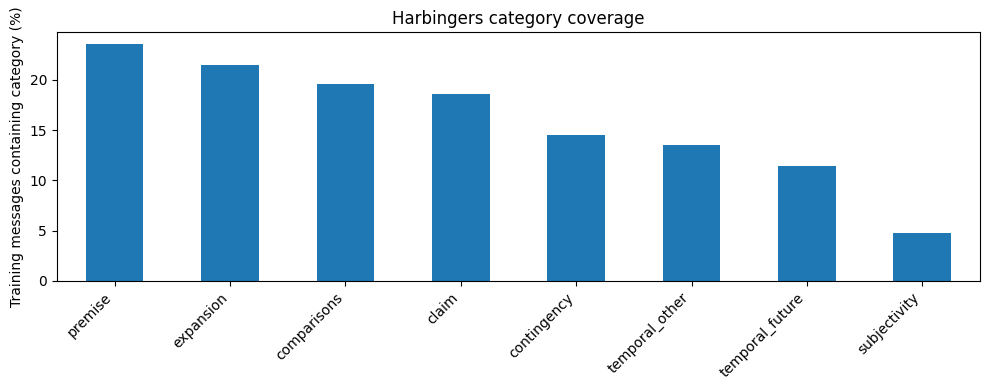

In [13]:
frequency_table["percent_of_messages"].plot.bar(figsize=(10, 4))
plt.ylabel("Training messages containing category (%)")
plt.title("Harbingers category coverage")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Count messages without Harbingers terms

In [14]:
actual_features["total_matches"] = actual_features[feature_names].sum(axis=1)
zero_count = int((actual_features["total_matches"] == 0).sum())
print("Messages with no category matches:", zero_count)
print("Percentage:", round(100 * zero_count / len(actual_features), 2))

Messages with no category matches: 6508
Percentage: 49.56


In [15]:
actual_df.loc[
    actual_features["total_matches"].eq(0), ["message_id", "message", "target"]
].head(5)

,message_id,message,target
1,1:0:1,"You've whet my appetite, Italy. What's the suggestion?",0
2,1:0:2,👍,0
6,1:0:6,Any thoughts?,0
7,1:0:7,"Sorry Italy I've been away doing, um, German things. Brewing Lagers?",0
13,1:0:13,Just an FYI: I’ve now had both England and France suggest to me that I should move to Tyrolia and France will support me to Mu...,0


#### Compare categories in truthful and deceptive messages


In [16]:
presence = (actual_features[feature_names] > 0).astype(int)
presence["target"] = actual_features["target"]

presence_rates = presence.groupby("target")[feature_names].mean().T * 100
presence_rates = presence_rates.rename(columns={0: "Truthful (%)", 1: "Deceptive (%)"})
presence_rates["Difference (deceptive - truthful)"] = (
    presence_rates["Deceptive (%)"] - presence_rates["Truthful (%)"]
)
presence_rates.round(2).sort_values("Difference (deceptive - truthful)", ascending=False)



target,Truthful (%),Deceptive (%),Difference (deceptive - truthful)
claim,18.10,29.44,11.34
premise,23.17,31.47,8.30
comparisons,19.32,25.04,5.72
expansion,21.30,24.87,3.57
contingency,14.39,17.77,3.37
temporal_other,13.38,16.58,3.20
temporal_future,11.36,14.04,2.68
subjectivity,4.70,7.28,2.58


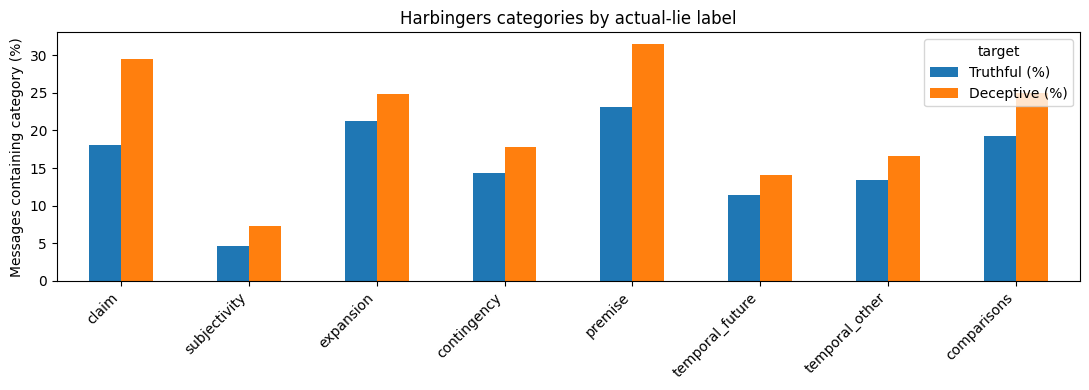

In [17]:
presence_rates[["Truthful (%)", "Deceptive (%)"]].plot.bar(figsize=(11, 4))
plt.ylabel("Messages containing category (%)")
plt.title("Harbingers categories by actual-lie label")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#### Normalize match counts by message length


In [18]:
word_counts = actual_df["message"].fillna("").astype(str).str.split().str.len().clip(lower=1)
rate_features = actual_features[feature_names].div(word_counts.to_numpy(), axis=0) * 100
rate_features["target"] = actual_features["target"]

rate_summary = rate_features.groupby("target")[feature_names].mean().T
rate_summary = rate_summary.rename(columns={0: "Truthful", 1: "Deceptive"})
rate_summary["Difference"] = rate_summary["Deceptive"] - rate_summary["Truthful"]
display(rate_summary.round(3))

target,Truthful,Deceptive,Difference
claim,1.047,1.173,0.125
subjectivity,0.246,0.259,0.014
expansion,1.218,1.219,0.001
contingency,0.685,0.753,0.068
premise,1.410,1.599,0.189
temporal_future,0.576,0.685,0.108
temporal_other,0.666,0.688,0.022
comparisons,1.119,1.296,0.177


####category overlap

Two categories may share the same term or often appear in the same message. This helps explain potential feature redundancy.

In [19]:
terms_by_category = {
    category: set(term.strip().lower() for term in terms.split("|") if term.strip())
    for category, terms in LEXICON.items()
}
overlap_rows = []
for i, a in enumerate(feature_names):
    for b in feature_names[i + 1:]:
        shared = sorted(terms_by_category[a] & terms_by_category[b])
        if shared:
            overlap_rows.append({"category_1": a, "category_2": b,
                                 "shared_terms": len(shared), "examples": ", ".join(shared[:8])})

print("Category pairs sharing lexicon terms:", len(overlap_rows))


Category pairs sharing lexicon terms: 15


In [21]:
display(pd.DataFrame(overlap_rows).sort_values("shared_terms", ascending=False).head(15)
        if overlap_rows else pd.DataFrame())

,category_1,category_2,shared_terms,examples
7,expansion,comparisons,20,"although, as if, as though, besides, however, in fact, in the end, indeed"
3,expansion,contingency,8,"in the end, in turn, indeed, lest, then, unless, until, when"
5,expansion,temporal_future,7,"finally, in the end, later, next, then, ultimately, until"
4,expansion,premise,6,"besides, for example, for instance, furthermore, in addition, moreover"
6,expansion,temporal_other,6,"also, in turn, meantime, meanwhile, when, while"
14,temporal_other,comparisons,6,"earlier, meanwhile, previously, still, when, while"
1,claim,contingency,6,"accordingly, as a result, consequently, hence, therefore, thus"
10,contingency,temporal_other,5,"as long as, in turn, now that, since, when"
9,contingency,temporal_future,4,"in the end, once, then, until"
11,contingency,comparisons,4,"in the end, indeed, then, when"




Look at actual messages in which a selected category occurs. These are illustrative, not evidence of intent or causation.

In [22]:
CATEGORY = "claim"  # Change to any name shown in feature_names
assert CATEGORY in feature_names

examples = actual_features.loc[
    actual_features[CATEGORY] > 0, ["message_id", "target", CATEGORY]
].head(6)
examples = examples.merge(actual_df[["message_id", "message"]], on="message_id", how="left")
examples

,message_id,target,claim,message
0,1:0:0,0,1.0,"Germany!\n\nJust the person I want to speak with. I have a somewhat crazy idea that I’ve always wanted to try with I/G, but I’..."
1,1:0:4,0,4.0,"Yeah, I can’t say I’ve tried it and it works, cause I’ve never tried it or seen it. But how I think it would work is (a) my Sp..."
2,1:0:5,0,1.0,"I am just sensing that you don’t like this idea, so shall we talk about something else? That was just a crazy idea I’ve always..."
3,1:0:8,0,1.0,"I don't think I'm ready to go for that idea, however I'd be down for some good ol'-fashioned Austria-kicking?"
4,1:0:10,0,2.0,"But I think I can get over “Lagergate” and we can still be friends. \n\nAs of right now, I think Austria may be my most reliab..."
5,1:0:14,0,1.0,"I appreciate the tip, but I'm wondering why you're so against ousting me from Munich if I haven't explicitly agreed to be your..."


#### Compare the suspected-lie task separately

In [23]:
suspected_df = datasets["suspected_lie"].copy()
X_suspected = harbingers_features(
    suspected_df["message"].fillna("").astype(str).tolist()
)
suspected_features = pd.DataFrame(X_suspected, columns=feature_names)
suspected_features["target"] = suspected_df["target"].values

suspected_presence = (suspected_features[feature_names] > 0).astype(int)
suspected_presence["target"] = suspected_features["target"]
suspected_rates = suspected_presence.groupby("target")[feature_names].mean().T * 100
suspected_rates = suspected_rates.rename(columns={0: "Not suspected (%)", 1: "Suspected (%)"})
suspected_rates.round(2)


target,Not suspected (%),Suspected (%)
claim,18.56,19.43
subjectivity,4.87,5.12
expansion,21.40,24.03
contingency,14.52,16.61
premise,23.52,27.03
temporal_future,11.37,12.19
temporal_other,13.45,15.19
comparisons,19.43,22.97


In [24]:

print("Suspected-lie training messages:", len(suspected_df))
print("Feature matrix shape:", X_suspected.shape)

Suspected-lie training messages: 12025
Feature matrix shape: (12025, 8)


#### Compare category differences across the two tasks


In [25]:
comparison = pd.DataFrame({
    "actual_lie_difference_pp": presence_rates["Difference (deceptive - truthful)"],
    "suspected_lie_difference_pp": (
        suspected_rates["Suspected (%)"] - suspected_rates["Not suspected (%)"]
    )
})
comparison.round(2)



,actual_lie_difference_pp,suspected_lie_difference_pp
claim,11.34,0.87
subjectivity,2.58,0.25
expansion,3.57,2.63
contingency,3.37,2.09
premise,8.30,3.51
temporal_future,2.68,0.82
temporal_other,3.20,1.75
comparisons,5.72,3.53


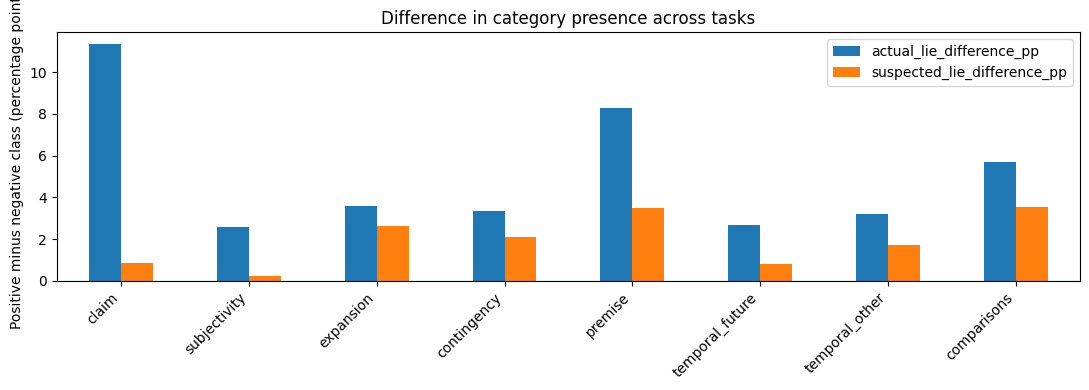

In [26]:
comparison.plot.bar(figsize=(11, 4))
plt.ylabel("Positive minus negative class (percentage points)")
plt.title("Difference in category presence across tasks")
plt.axhline(0, linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()